# Moving one design lever at a time: how three predictors respond when the burden, the spacing or the powder factor changes

**Question:** Which design levers does each predictor respond to?

**Level 1: Fundamentals** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast, 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Reading time: about 30 minutes

## Objectives

A blast engineer rarely asks for one number. The question is what happens if the burden is tightened, the spacing opened or the powder factor raised. The product answers it by changing one lever of a design at a time and predicting again, and it shows the response of every predictor. This notebook does that for a whole campaign, the 22 blasts of Akdaglar, and for three kinds of predictor: a closed-form equation, a fitted power law and a learned model.

By the end you will have:

- applied each of the product's eight standard variants to the 22 blasts and predicted the result with the classical equation, the published regression and gradient boosting, one variant per cell;
- worked out on paper how much each of the first two should respond to each lever, and found the paper and the engine agree to a tenth of a percent;
- seen which levers each predictor ignores, which ones it follows, and what the campaign mean hides about a learned model.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The setup cell imports the packages and the product's own variant tools from `data-pipeline/pipeline`: the registry of cases, `apply_variant`, which moves one field of a blast by a multiplier and drops its measured size because a perturbed design has never been fired, and `is_degenerate`, which rejects a design that is no longer a blast. It prints the versions, loads the Akdaglar case and defines `mean_prediction`, the mean predicted size over the designs that are still a blast, and `Table`.

In [1]:
# Imports, package versions and the corpus loader
from importlib.metadata import version
from pathlib import Path
import sys

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.model.blasts import apply_variant, blasts_for_case, is_degenerate
from pipeline.registry import get_case

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

train = bf.load_training_corpus()

class Table:
    """Rows under a header, shown as a Markdown table"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

case = get_case("real-akdaglar")
blasts = blasts_for_case(case)
variants = {variant.id: variant for variant in case.variants}


def mean_prediction(arm, designs):
    """Mean predicted size over the designs that are still a blast, skipping any refusal"""
    valid = [design for design in designs if is_degenerate(design) is None]
    answers = [p.x50_m for p in arm.predict(valid) if not p.abstained]
    return float(np.mean(answers))

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 22 Akdaglar blasts and the rest of the corpus, used to train gradient boosting | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The case registry and the eight standard variants | this repository (MIT) | the product's own licence | `data-pipeline/pipeline/registry.py` and `pipeline/model/blasts.py`, imported by path |

A variant moves one field of a blast by a multiplier. The response is a set of predictions for a design nobody fired, never scored against a measurement.

## Method

For each variant `v` and each blast `b` of the campaign, `apply_variant(b, v)` returns a copy with one field multiplied. The predictor answers each copy, and the response of the predictor to `v` is the mean predicted size over the 22 blasts, so the spread of the campaign is carried into the response instead of being replaced by one blast.

The three predictors span the ladder. The classical equation (Kuznetsov 1973, with Cunningham's correction, as printed by Hudaverdi et al. 2010 and Amoako et al. 2022) is `x50 = A (V/Q)^0.8 Q^(1/6) (RWS/115)^(-19/30)`, where `V` is the rock volume per hole, `Q` the explosive mass in it and `A` the rock factor. The published regression is a power law of the seven design ratios with exponents fitted on the corpus (Hudaverdi et al. 2010). Gradient boosting is trained here on the blasts that are not from Akdaglar, so it has not seen the campaign it is asked to respond for.

The classical response can be worked out before running anything. The variants change ratios, and the diameter stays fixed, so a burden multiplier scales every length of the pattern and the volume per hole grows as the cube of the burden. At a fixed powder factor `Q` is proportional to `V`, so `x50` goes as `B^(1/2)`. A spacing multiplier stretches the spacing alone, so `V` grows linearly with it and `x50` as `S^(1/6)`. A powder factor `Pf` enters twice, as `V/Q = 1/Pf` and through `Q = Pf V`, giving `Pf^(-0.8 + 1/6) = Pf^(-19/30)`. The stemming and the in situ block size appear nowhere in the equation, so their exponent is zero.

### Step 1: the case, its eight variants and the three predictors

The cell lists the variants of the Akdaglar case with the field each one moves and its multiplier, and builds the three predictors. The classical one receives the engine's table of per-site rock factors, as the product does.

In [2]:
# The eight variants of the Akdaglar case and the three predictors: classical, published regression, gradient boosting
for variant in variants.values():
    print(f"{variant.id:<14} {variant.field:<9} x {variant.factor:<5} {variant.label_en}")
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([blast for blast in train if blast.site != case.site]),
}
response = {}

base           none      x 1.0   As designed
burden-tight   B_over_D  x 0.85  Burden 15 percent tighter
burden-wide    B_over_D  x 1.15  Burden 15 percent wider
spacing-wide   S_over_B  x 1.2   Spacing 20 percent wider
powder-up      Pf_kg_m3  x 1.3   Powder factor 30 percent higher
powder-down    Pf_kg_m3  x 0.75  Powder factor 25 percent lower
stemming-long  T_over_B  x 1.25  Stemming 25 percent longer
blocky         XB_m      x 1.5   In situ blocks 50 percent larger


### Step 2: one variant per cell

**The base design** is the reference: the `base` variant moves nothing, so the cell predicts the 22 blasts as they were fired. Every other variant is read as a change from these three numbers, and the level already differs: the three predictors do not agree on how coarse the campaign is.

In [3]:
# Predict the campaign as designed
designs = [apply_variant(blast, variants["base"]) for blast in blasts]
response["base"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("base", {name: round(value, 4) for name, value in response["base"].items()})

base {'kuznetsov': 0.1593, 'published-regression': 0.1795, 'xgboost': 0.2454}


**Burden 15 percent tighter** multiplies `B/D` by 0.85. A tighter pattern puts the same hole closer to its neighbours and less rock on each charge, so a physical predictor should answer with finer rock. On paper the classical equation gives 0.85^(1/2).

In [4]:
# Burden 15 percent tighter, then predict
designs = [apply_variant(blast, variants["burden-tight"]) for blast in blasts]
response["burden-tight"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("burden-tight", {name: round(value, 4) for name, value in response["burden-tight"].items()})

burden-tight {'kuznetsov': 0.1469, 'published-regression': 0.1675, 'xgboost': 0.2524}


**Burden 15 percent wider** multiplies `B/D` by 1.15, the mirror lever. The classical equation predicts 1.15^(1/2), and a predictor that is a smooth function of the inputs should answer with the opposite sign of the previous cell.

In [5]:
# Burden 15 percent wider, then predict
designs = [apply_variant(blast, variants["burden-wide"]) for blast in blasts]
response["burden-wide"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("burden-wide", {name: round(value, 4) for name, value in response["burden-wide"].items()})

burden-wide {'kuznetsov': 0.1709, 'published-regression': 0.1905, 'xgboost': 0.2441}


**Spacing 20 percent wider** multiplies `S/B` by 1.2 and leaves the burden alone, so the volume per hole grows by 20 percent and the classical `x50` by 1.2^(1/6). This lever separates the predictors: the classical exponent is small, and the regression carries a larger one for `S/B`.

In [6]:
# Spacing 20 percent wider, then predict
designs = [apply_variant(blast, variants["spacing-wide"]) for blast in blasts]
response["spacing-wide"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("spacing-wide", {name: round(value, 4) for name, value in response["spacing-wide"].items()})

spacing-wide {'kuznetsov': 0.1643, 'published-regression': 0.1983, 'xgboost': 0.2402}


**Powder factor 30 percent higher** multiplies `Pf` by 1.3: more explosive per cubic metre. The classical exponent is -19/30, so more charge should make the rock finer, and this is the strongest lever of the equation. The regression has a much smaller exponent for the powder factor.

In [7]:
# Powder factor 30 percent higher, then predict
designs = [apply_variant(blast, variants["powder-up"]) for blast in blasts]
response["powder-up"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("powder-up", {name: round(value, 4) for name, value in response["powder-up"].items()})

powder-up {'kuznetsov': 0.1349, 'published-regression': 0.1742, 'xgboost': 0.2456}


**Powder factor 25 percent lower** multiplies `Pf` by 0.75, the mirror lever, and the one where the classical equation should predict the largest change: 0.75 raised to -19/30 is a coarsening of about a fifth, which the table of step 3 puts at +20.0 percent.

In [8]:
# Powder factor 25 percent lower, then predict
designs = [apply_variant(blast, variants["powder-down"]) for blast in blasts]
response["powder-down"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("powder-down", {name: round(value, 4) for name, value in response["powder-down"].items()})

powder-down {'kuznetsov': 0.1912, 'published-regression': 0.1855, 'xgboost': 0.2389}


**Stemming 25 percent longer** multiplies `T/B` by 1.25. Stemming is the inert column at the top of the hole, and the classical equation has no term for it: its answer must be exactly the base value. A predictor that fits `T/B` as an input will answer something else, and that difference is a finding, not a bug.

In [9]:
# Stemming 25 percent longer, then predict
designs = [apply_variant(blast, variants["stemming-long"]) for blast in blasts]
response["stemming-long"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("stemming-long", {name: round(value, 4) for name, value in response["stemming-long"].items()})

stemming-long {'kuznetsov': 0.1593, 'published-regression': 0.1755, 'xgboost': 0.2528}


**In situ blocks 50 percent larger** multiplies `XB` by 1.5, a coarser rock mass before any blast. The classical equation has no term for it either, since the rock factor is a constant per campaign; the regression and the learned model take `XB` as an input.

In [10]:
# In situ blocks 50 percent larger, then predict
designs = [apply_variant(blast, variants["blocky"]) for blast in blasts]
response["blocky"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("blocky", {name: round(value, 4) for name, value in response["blocky"].items()})

blocky {'kuznetsov': 0.1593, 'published-regression': 0.214, 'xgboost': 0.2672}


### Step 3: the change against the base design, and the paper

Absolute sizes hide the lever, so the cell converts every response to the percentage change from the base design. It then computes what each closed form says on paper: the classical exponents of the Method section, and for the regression the exponent it carries for each field, `factor ^ exponent`. The table sets measured and paper side by side, and the figure draws them.

In [11]:
# Percentage change against the base design, beside what the classical equation predicts on paper
levers = [vid for vid in variants if vid != "base"]
exponent = {"burden-tight": 1 / 2, "burden-wide": 1 / 2, "spacing-wide": 1 / 6, "powder-up": -19 / 30,
    "powder-down": -19 / 30,
            "stemming-long": 0.0, "blocky": 0.0}
change = {name: [100 * (response[vid][name] / response["base"][name] - 1) for vid in levers] for name in arms}
on_paper = [100 * (variants[vid].factor ** exponent[vid] - 1) for vid in levers]
fitted = bf.PublishedRegression().coefficients[2].exponents
print("published regression, exponents of the low-modulus group:", fitted)
regression_on_paper = [100 * (variants[vid].factor ** fitted[variants[vid].field] - 1) for vid in levers]
rows = [(vid, f"{variants[vid].factor:g}", *(f"{change[name][k]:+.1f}" for name in arms), f"{on_paper[k]:+.1f}",
    f"{regression_on_paper[k]:+.1f}")
        for k, vid in enumerate(levers)]
Table(["variant", "multiplier", *arms, "classical on paper", "regression on paper"], rows)

published regression, exponents of the low-modulus group: {'S_over_B': 0.547, 'H_over_B': 0.535, 'B_over_D': 0.427, 'T_over_B': -0.101, 'Pf_kg_m3': -0.115, 'XB_m': 0.434, 'E_GPa': -1.202}


| variant | multiplier | kuznetsov | published-regression | xgboost | classical on paper | regression on paper |
|---|---|---|---|---|---|---|
| burden-tight | 0.85 | -7.8 | -6.7 | +2.9 | -7.8 | -6.7 |
| burden-wide | 1.15 | +7.2 | +6.1 | -0.5 | +7.2 | +6.1 |
| spacing-wide | 1.2 | +3.1 | +10.5 | -2.1 | +3.1 | +10.5 |
| powder-up | 1.3 | -15.3 | -3.0 | +0.1 | -15.3 | -3.0 |
| powder-down | 0.75 | +20.0 | +3.4 | -2.6 | +20.0 | +3.4 |
| stemming-long | 1.25 | +0.0 | -2.2 | +3.0 | +0.0 | -2.2 |
| blocky | 1.5 | +0.0 | +19.2 | +8.9 | +0.0 | +19.2 |

The next cell draws the table of step 3 as grouped bars, one group per lever, and puts the two closed forms' paper values on top as diamonds. A bar that does not reach its diamond would mean the engine disagrees with the arithmetic, so look first at whether the blue and green bars meet theirs.

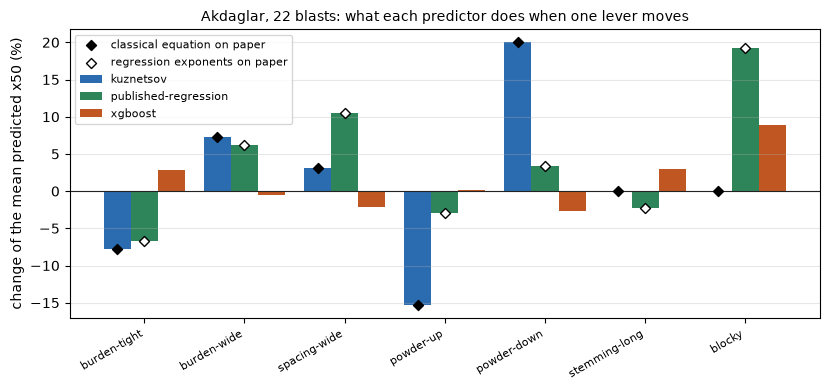

In [12]:
# Change in the mean predicted size per variant and predictor; diamonds: the exponents worked out on paper
colors = {"kuznetsov": "#2b6cb0", "published-regression": "#2f855a", "xgboost": "#c05621"}
x = np.arange(len(levers))
fig, ax = plt.subplots(figsize=(8.4, 4))
for k, name in enumerate(arms):
    ax.bar(x + (k - 1) * 0.27, change[name], 0.27, label=name, color=colors[name])
ax.scatter(x - 0.27, on_paper, marker="D", s=26, color="black", zorder=3, label="classical equation on paper")
ax.scatter(x, regression_on_paper, marker="D", s=26, color="white", edgecolor="black", zorder=3,
    label="regression exponents on paper")
ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(x, levers, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("change of the mean predicted x50 (%)")
ax.set_title("Akdaglar, 22 blasts: what each predictor does when one lever moves", fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** The black diamonds sit on the blue bars: the classical response is exactly what the equation says, for example -15.3 percent for the higher powder factor and +20.0 percent for the lower one, and zero for the stemming and the blocks, which the equation does not contain. The white diamonds sit on the green bars too: the regression's response is its fitted exponent, +10.5 percent for the wider spacing against +3.1 for the classical one, and -2.2 percent for the longer stemming. The orange bars, gradient boosting, follow neither: +2.9 percent for a tighter burden, +3.0 for longer stemming and +8.9 for larger blocks, and almost nothing for the powder factor. **What it does not show:** which response is right, because no dataset records one pit blasted twice with one lever changed. **What follows:** the two closed forms disagree with each other on the spacing, the powder factor and the blocks, and the learned one is not a smooth function of any lever.

### Step 4: what the campaign mean hides

The mean over 22 blasts is a summary, and for a tree model the summary can mislead. The cell predicts each of the 22 blasts under every variant with gradient boosting, expresses the change for each blast as a percentage, and counts the blasts that do not move at all.

In [13]:
# The change blast by blast for gradient boosting: how many blasts do not move at all
boosting = arms["xgboost"]
base_sizes = [p.x50_m for p in boosting.predict(blasts)]
per_blast = {}
for vid in levers:
    moved = boosting.predict([apply_variant(blast, variants[vid]) for blast in blasts])
    per_blast[vid] = [100 * (p.x50_m / base - 1) for p, base in zip(moved, base_sizes)]
rows = [(vid, sum(abs(v) < 1e-9 for v in values), f"{min(values):+.1f}", f"{max(values):+.1f}") for vid,
    values in per_blast.items()]
Table(["variant", "blasts with no change (of 22)", "smallest change (%)", "largest change (%)"], rows)

| variant | blasts with no change (of 22) | smallest change (%) | largest change (%) |
|---|---|---|---|
| burden-tight | 7 | -4.8 | +11.9 |
| burden-wide | 6 | -6.8 | +8.3 |
| spacing-wide | 9 | -32.5 | +3.2 |
| powder-up | 15 | -4.3 | +2.6 |
| powder-down | 7 | -16.9 | +11.9 |
| stemming-long | 9 | -4.0 | +57.8 |
| blocky | 3 | -6.5 | +86.6 |

The next cell draws the blast-by-blast change of gradient boosting for each lever, one point per blast, with the classical equation's single value as a diamond. If the model were a smooth function of the lever, the points would stack at one height; look at how they spread and how many sit exactly at zero.

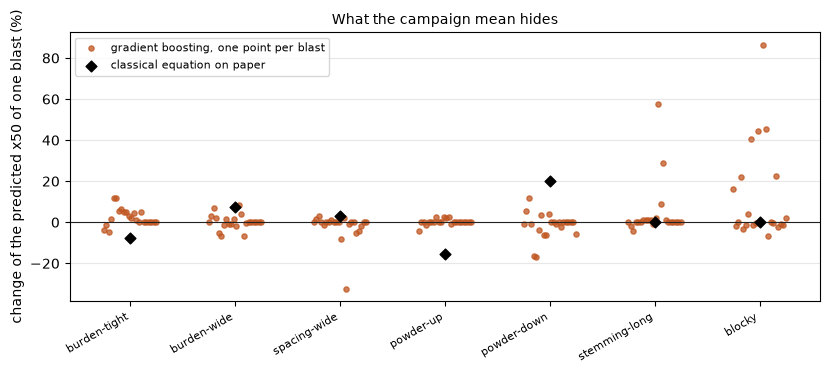

In [14]:
# Each blast's change under every variant for gradient boosting; the classical equation moves all blasts by one value
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for k, vid in enumerate(levers):
    ax.scatter(np.full(len(blasts), k) + np.linspace(-0.25, 0.25, len(blasts)), per_blast[vid], s=14, color="#c05621",
        alpha=0.75,
               label="gradient boosting, one point per blast" if k == 0 else None)
ax.scatter(x, on_paper, marker="D", s=30, color="black", zorder=3, label="classical equation on paper")
ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(x, levers, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("change of the predicted x50 of one blast (%)")
ax.set_title("What the campaign mean hides", fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** A tree ensemble is piecewise constant, so a blast that stays inside its leaf does not move: under the higher powder factor 15 of the 22 blasts keep exactly their base prediction, and under the lower one 7. A blast that crosses a split jumps: a longer stemming moves one blast by +57.8 percent and larger blocks move one by +86.6 percent, against a campaign mean of +3.0 and +8.9 percent. The black diamonds, the classical equation, move every blast by the same amount. **What it does not show:** that the jumps are wrong, only that they are not a response to a small change but to a threshold in the training data. **What follows:** a design view built on a learned predictor should show blast by blast, not only the mean.

## Results

**Answer:** the classical equation responds to the three levers it contains and to nothing else, the published regression to every input it has with exponents that it fitted, and gradient boosting to a different set of levers and in steps. The classical equation moves by -7.8 percent for the tighter burden, +3.1 for the wider spacing, -15.3 for the higher powder factor and +20.0 for the lower one, and by exactly 0.0 for the longer stemming and the larger blocks. The regression follows its exponents (-6.7, +10.5, -3.0, +3.4, and -2.2 and +19.2 for the two levers the equation ignores). Gradient boosting moves by +2.9 percent when the burden is tightened and +0.1 when the powder factor is raised, and 15 of the 22 blasts do not move under that variant.

The two closed forms are exact to their paper: the table of step 3 shows the engine and the exponents agreeing to the tenth of a percent in every row, so the response is the arithmetic of the equation and not an artifact. They disagree about the world: the classical equation makes the powder factor its strongest lever and the regression one of its weakest; the regression makes the blocks the strongest, and the equation ignores them.

**What this does not show.** These are responses of models, not of blasts. The corpus holds different blasts at different pits, so a fitted exponent reflects how blasts differ across pits, not what happens when one lever is turned on one blast. The product therefore labels these curves as the response of the model and never as a forecast.

## Summary

- A variant moves one field of a blast by a multiplier, drops the measurement and predicts again; the response of a predictor is the mean over the 22 blasts of the campaign.
- The classical response can be worked out on paper (`B^(1/2)`, `S^(1/6)`, `Pf^(-19/30)`, nothing for stemming and blocks) and the engine reproduces it; the regression's response is its fitted exponent.
- Gradient boosting responds in steps: 15 of 22 blasts do not move under the higher powder factor, and single blasts jump by up to +86.6 percent.
- Next: notebook 02 sweeps two levers at once, the burden and the spacing, and compares the three surfaces.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector regression, rbf kernel; the classical equation)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (support vector polynomial, forest, boosting, stacking)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/